In [1]:
from pathlib import Path
import sys
import cv2
import pandas as pd
import numpy as np

print("Python:", sys.version)
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Python: 3.12.3 (main, Jun 19 2026, 12:46:00) [GCC 13.3.0]
OpenCV: 5.0.0
NumPy: 2.3.5
Pandas: 2.3.3


In [2]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent.parent
SPORTSMOT_DIR = (
    PROJECT_ROOT
    / "datasets"
    / "football"
    / "benchmarks"
    / "sportsmot"
    / "extracted"
)

YOLO_DIR = (
    PROJECT_ROOT
    / "datasets"
    / "football"
    / "processed"
    / "sportsmot_yolo"
)

print("Project root:")
print(PROJECT_ROOT)

print("\nSportsMOT input:")
print(SPORTSMOT_DIR)

print("\nYOLO output:")
print(YOLO_DIR)

print("\nInput exists :", SPORTSMOT_DIR.exists())
print("Output exists:", YOLO_DIR.exists())

Project root:
/mnt/d/My Projects/AthletiQ/AthletiQ

SportsMOT input:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted

YOLO output:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/sportsmot_yolo

Input exists : True
Output exists: False


In [3]:
if YOLO_DIR.exists():
    existing_files = list(YOLO_DIR.rglob("*"))

    print("WARNING: Output directory already exists.")
    print(f"Items found: {len(existing_files)}")

    if existing_files:
        print("Do NOT continue yet — we need to inspect the directory.")
    else:
        print("Directory is empty and safe to use.")
else:
    print("Output directory does not exist.")
    print("Safe to create.")

Output directory does not exist.
Safe to create.


In [4]:
YOLO_TRAIN_IMAGES = YOLO_DIR / "images" / "train"
YOLO_VAL_IMAGES = YOLO_DIR / "images" / "val"

YOLO_TRAIN_LABELS = YOLO_DIR / "labels" / "train"
YOLO_VAL_LABELS = YOLO_DIR / "labels" / "val"

for directory in [
    YOLO_TRAIN_IMAGES,
    YOLO_VAL_IMAGES,
    YOLO_TRAIN_LABELS,
    YOLO_VAL_LABELS
]:
    directory.mkdir(parents=True, exist_ok=True)

print("YOLO dataset directories created:")
print()

for directory in [
    YOLO_TRAIN_IMAGES,
    YOLO_VAL_IMAGES,
    YOLO_TRAIN_LABELS,
    YOLO_VAL_LABELS
]:
    print(directory)

YOLO dataset directories created:

/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/sportsmot_yolo/images/train
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/sportsmot_yolo/images/val
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/sportsmot_yolo/labels/train
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/sportsmot_yolo/labels/val


In [5]:
# Test MOT → YOLO conversion on one frame

sequence = sorted((SPORTSMOT_DIR / "train").iterdir())[0]

image_path = sequence / "img1" / "000001.jpg"
gt_file = sequence / "gt" / "gt.txt"

# Read image dimensions
image = cv2.imread(str(image_path))
image_height, image_width = image.shape[:2]

# Read GT
gt = pd.read_csv(
    gt_file,
    header=None,
    names=[
        "frame",
        "track_id",
        "x",
        "y",
        "width",
        "height",
        "mark",
        "class",
        "visibility"
    ]
)

# Get annotations for frame 1
frame_gt = gt[gt["frame"] == 1]

yolo_labels = []

for _, row in frame_gt.iterrows():

    x = float(row["x"])
    y = float(row["y"])
    w = float(row["width"])
    h = float(row["height"])

    # MOT → YOLO center coordinates
    x_center = x + (w / 2)
    y_center = y + (h / 2)

    # Normalize
    x_center /= image_width
    y_center /= image_height
    w_normalized = w / image_width
    h_normalized = h / image_height

    # SportsMOT class 1 → YOLO class 0
    class_id = 0

    yolo_labels.append([
        class_id,
        x_center,
        y_center,
        w_normalized,
        h_normalized
    ])

print("Sequence:", sequence.name)
print("Image:", image_path.name)
print("Image size:", image_width, "x", image_height)
print("Objects:", len(yolo_labels))

print("\nFirst YOLO labels:")
for label in yolo_labels[:10]:
    print(
        f"{label[0]} "
        f"{label[1]:.6f} "
        f"{label[2]:.6f} "
        f"{label[3]:.6f} "
        f"{label[4]:.6f}"
    )

Sequence: v_1yHWGw8DH4A_c029
Image: 000001.jpg
Image size: 1280 x 720
Objects: 8

First YOLO labels:
0 0.550781 0.594444 0.023438 0.119444
0 0.496094 0.367361 0.026562 0.095833
0 0.779687 0.350000 0.021875 0.094444
0 0.180469 0.295139 0.015625 0.081944
0 0.039844 0.283333 0.025000 0.075000
0 0.012500 0.546528 0.025000 0.115278
0 0.134375 0.534722 0.018750 0.113889
0 0.117188 0.378472 0.018750 0.090278


In [6]:
# Write one test image and YOLO label

test_image_output = YOLO_TRAIN_IMAGES / sequence.name / image_path.name
test_label_output = YOLO_TRAIN_LABELS / sequence.name / (
    image_path.stem + ".txt"
)

test_image_output.parent.mkdir(parents=True, exist_ok=True)
test_label_output.parent.mkdir(parents=True, exist_ok=True)

# Copy image
import shutil

shutil.copy2(image_path, test_image_output)

# Write YOLO labels
with open(test_label_output, "w") as f:
    for label in yolo_labels:
        f.write(
            f"{label[0]} "
            f"{label[1]:.6f} "
            f"{label[2]:.6f} "
            f"{label[3]:.6f} "
            f"{label[4]:.6f}\n"
        )

print("Test conversion written successfully.")
print()
print("Image:")
print(test_image_output)
print()
print("Label:")
print(test_label_output)
print()
print("Image exists :", test_image_output.exists())
print("Label exists :", test_label_output.exists())
print()
print("Label contents:")
print(test_label_output.read_text())

Test conversion written successfully.

Image:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/sportsmot_yolo/images/train/v_1yHWGw8DH4A_c029/000001.jpg

Label:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/sportsmot_yolo/labels/train/v_1yHWGw8DH4A_c029/000001.txt

Image exists : True
Label exists : True

Label contents:
0 0.550781 0.594444 0.023438 0.119444
0 0.496094 0.367361 0.026562 0.095833
0 0.779687 0.350000 0.021875 0.094444
0 0.180469 0.295139 0.015625 0.081944
0 0.039844 0.283333 0.025000 0.075000
0 0.012500 0.546528 0.025000 0.115278
0 0.134375 0.534722 0.018750 0.113889
0 0.117188 0.378472 0.018750 0.090278



In [7]:
# Verify that YOLO coordinates reconstruct the original MOT bounding boxes

print("Verifying YOLO ↔ MOT bounding-box conversion...\n")

errors = []

for _, row in frame_gt.iterrows():

    # Original MOT bbox
    mot_x = float(row["x"])
    mot_y = float(row["y"])
    mot_w = float(row["width"])
    mot_h = float(row["height"])

    # Convert MOT → YOLO
    yolo_xc = (mot_x + mot_w / 2) / image_width
    yolo_yc = (mot_y + mot_h / 2) / image_height
    yolo_w = mot_w / image_width
    yolo_h = mot_h / image_height

    # Convert YOLO → pixel coordinates
    reconstructed_w = yolo_w * image_width
    reconstructed_h = yolo_h * image_height

    reconstructed_x = (
        yolo_xc * image_width
        - reconstructed_w / 2
    )

    reconstructed_y = (
        yolo_yc * image_height
        - reconstructed_h / 2
    )

    errors.append([
        abs(mot_x - reconstructed_x),
        abs(mot_y - reconstructed_y),
        abs(mot_w - reconstructed_w),
        abs(mot_h - reconstructed_h)
    ])

errors = np.array(errors)

print("Maximum absolute error:")
print(f"X      : {errors[:, 0].max():.10f} pixels")
print(f"Y      : {errors[:, 1].max():.10f} pixels")
print(f"Width  : {errors[:, 2].max():.10f} pixels")
print(f"Height : {errors[:, 3].max():.10f} pixels")

print("\nMean absolute error:")
print(f"X      : {errors[:, 0].mean():.10f} pixels")
print(f"Y      : {errors[:, 1].mean():.10f} pixels")
print(f"Width  : {errors[:, 2].mean():.10f} pixels")
print(f"Height : {errors[:, 3].mean():.10f} pixels")

if errors.max() < 0.01:
    print("\nPASS: YOLO conversion is correct.")
else:
    print("\nWARNING: Conversion error detected.")

Verifying YOLO ↔ MOT bounding-box conversion...

Maximum absolute error:
X      : 0.0000000000 pixels
Y      : 0.0000000000 pixels
Width  : 0.0000000000 pixels
Height : 0.0000000000 pixels

Mean absolute error:
X      : 0.0000000000 pixels
Y      : 0.0000000000 pixels
Width  : 0.0000000000 pixels
Height : 0.0000000000 pixels

PASS: YOLO conversion is correct.


In [8]:
# Convert the complete SportsMOT Football dataset to YOLO format

import shutil
from tqdm.auto import tqdm

def convert_split(split_name, output_images_dir, output_labels_dir):
    
    split_dir = SPORTSMOT_DIR / split_name
    sequences = sorted([p for p in split_dir.iterdir() if p.is_dir()])
    
    total_frames = 0
    total_annotations = 0
    
    print(f"\nConverting {split_name.upper()} split...")
    print(f"Sequences: {len(sequences)}")
    
    for sequence in tqdm(sequences, desc=f"{split_name} sequences"):
        
        image_dir = sequence / "img1"
        gt_file = sequence / "gt" / "gt.txt"
        
        output_image_seq = output_images_dir / sequence.name
        output_label_seq = output_labels_dir / sequence.name
        
        output_image_seq.mkdir(parents=True, exist_ok=True)
        output_label_seq.mkdir(parents=True, exist_ok=True)
        
        # Read image dimensions from first image
        first_image = next(image_dir.glob("*.jpg"))
        image = cv2.imread(str(first_image))
        
        if image is None:
            raise RuntimeError(f"Could not read image: {first_image}")
        
        image_height, image_width = image.shape[:2]
        
        # Read MOT annotations
        gt = pd.read_csv(
            gt_file,
            header=None,
            names=[
                "frame",
                "track_id",
                "x",
                "y",
                "width",
                "height",
                "mark",
                "class",
                "visibility"
            ]
        )
        
        # Group annotations by frame
        frame_groups = gt.groupby("frame")
        
        image_files = sorted(image_dir.glob("*.jpg"))
        
        for image_path in image_files:
            
            frame_number = int(image_path.stem)
            
            # Output paths
            output_image = output_image_seq / image_path.name
            output_label = output_label_seq / f"{image_path.stem}.txt"
            
            # Copy image
            shutil.copy2(image_path, output_image)
            
            # Get annotations for this frame
            if frame_number in frame_groups.groups:
                frame_gt = frame_groups.get_group(frame_number)
            else:
                frame_gt = pd.DataFrame()
            
            yolo_lines = []
            
            for _, row in frame_gt.iterrows():
                
                # Only valid player annotations
                if int(row["mark"]) != 1:
                    continue
                
                if int(row["class"]) != 1:
                    continue
                
                x = float(row["x"])
                y = float(row["y"])
                w = float(row["width"])
                h = float(row["height"])
                
                # MOT → YOLO
                x_center = (x + w / 2) / image_width
                y_center = (y + h / 2) / image_height
                w_normalized = w / image_width
                h_normalized = h / image_height
                
                # YOLO class 0 = player
                class_id = 0
                
                yolo_lines.append(
                    f"{class_id} "
                    f"{x_center:.6f} "
                    f"{y_center:.6f} "
                    f"{w_normalized:.6f} "
                    f"{h_normalized:.6f}"
                )
            
            # Write label file
            output_label.write_text(
                "\n".join(yolo_lines) + ("\n" if yolo_lines else "")
            )
            
            total_frames += 1
            total_annotations += len(yolo_lines)
    
    print(f"\n{split_name.upper()} conversion complete.")
    print(f"Frames converted      : {total_frames:,}")
    print(f"Annotations converted : {total_annotations:,}")
    
    return total_frames, total_annotations


train_frames, train_annotations = convert_split(
    "train",
    YOLO_TRAIN_IMAGES,
    YOLO_TRAIN_LABELS
)

val_frames, val_annotations = convert_split(
    "val",
    YOLO_VAL_IMAGES,
    YOLO_VAL_LABELS
)

print("\n" + "=" * 50)
print("FULL CONVERSION COMPLETE")
print("=" * 50)

print(f"Train frames       : {train_frames:,}")
print(f"Train annotations  : {train_annotations:,}")
print(f"Val frames         : {val_frames:,}")
print(f"Val annotations    : {val_annotations:,}")

print(f"\nTotal frames       : {train_frames + val_frames:,}")
print(f"Total annotations  : {train_annotations + val_annotations:,}")

/home/jatin/tf312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Converting TRAIN split...
Sequences: 15


train sequences: 100%|████████████████| 15/15 [49:37<00:00, 198.53s/it]



TRAIN conversion complete.
Frames converted      : 11,113
Annotations converted : 145,228

Converting VAL split...
Sequences: 15


val sequences: 100%|██████████████████| 15/15 [36:18<00:00, 145.23s/it]


VAL conversion complete.
Frames converted      : 9,058
Annotations converted : 117,115

FULL CONVERSION COMPLETE
Train frames       : 11,113
Train annotations  : 145,228
Val frames         : 9,058
Val annotations    : 117,115

Total frames       : 20,171
Total annotations  : 262,343


In [9]:
# Verify YOLO dataset file integrity

def verify_yolo_split(image_dir, label_dir, split_name):
    
    images = sorted(image_dir.rglob("*.jpg"))
    labels = sorted(label_dir.rglob("*.txt"))
    
    image_stems = {
        (p.parent.relative_to(image_dir), p.stem)
        for p in images
    }
    
    label_stems = {
        (p.parent.relative_to(label_dir), p.stem)
        for p in labels
    }
    
    missing_labels = image_stems - label_stems
    orphan_labels = label_stems - image_stems
    
    empty_labels = [
        p for p in labels
        if p.stat().st_size == 0
    ]
    
    print(f"\n{split_name.upper()} SPLIT")
    print("-" * 40)
    print(f"Images        : {len(images):,}")
    print(f"Labels        : {len(labels):,}")
    print(f"Missing labels: {len(missing_labels):,}")
    print(f"Orphan labels : {len(orphan_labels):,}")
    print(f"Empty labels  : {len(empty_labels):,}")
    
    return {
        "images": images,
        "labels": labels,
        "missing_labels": missing_labels,
        "orphan_labels": orphan_labels,
        "empty_labels": empty_labels
    }


train_check = verify_yolo_split(
    YOLO_TRAIN_IMAGES,
    YOLO_TRAIN_LABELS,
    "train"
)

val_check = verify_yolo_split(
    YOLO_VAL_IMAGES,
    YOLO_VAL_LABELS,
    "val"
)


TRAIN SPLIT
----------------------------------------
Images        : 11,113
Labels        : 11,113
Missing labels: 0
Orphan labels : 0
Empty labels  : 0

VAL SPLIT
----------------------------------------
Images        : 9,058
Labels        : 9,058
Missing labels: 0
Orphan labels : 0
Empty labels  : 0


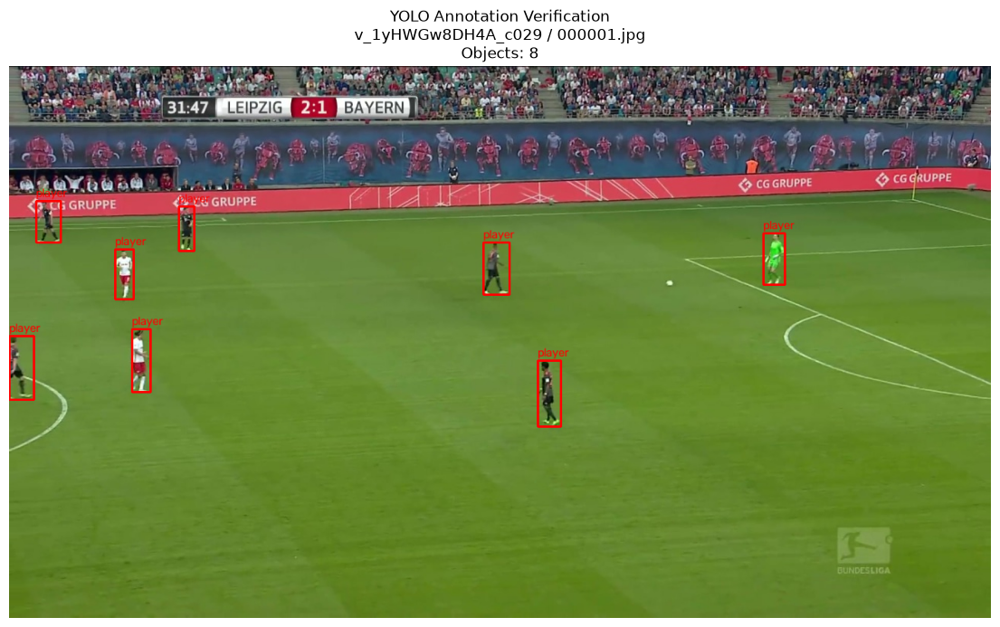

Image: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/sportsmot_yolo/images/train/v_1yHWGw8DH4A_c029/000001.jpg
Label: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/sportsmot_yolo/labels/train/v_1yHWGw8DH4A_c029/000001.txt
Image size: 1280 x 720
Objects: 8


In [10]:
# Cell 10 — Visual verification of converted YOLO annotations

import matplotlib.pyplot as plt
import cv2

# Use the same sequence/frame we validated earlier
sequence_name = "v_1yHWGw8DH4A_c029"
frame_name = "000001"

image_path = (
    YOLO_TRAIN_IMAGES
    / sequence_name
    / f"{frame_name}.jpg"
)

label_path = (
    YOLO_TRAIN_LABELS
    / sequence_name
    / f"{frame_name}.txt"
)

# Load image
image = cv2.imread(str(image_path))

if image is None:
    raise RuntimeError(f"Could not load image: {image_path}")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

image_height, image_width = image.shape[:2]

# Read YOLO labels
with open(label_path, "r") as f:
    lines = [line.strip() for line in f if line.strip()]

# Draw bounding boxes
for line in lines:

    class_id, x_center, y_center, width, height = map(
        float, line.split()
    )

    # YOLO normalized → pixel coordinates
    x_center *= image_width
    y_center *= image_height
    width *= image_width
    height *= image_height

    x1 = int(x_center - width / 2)
    y1 = int(y_center - height / 2)
    x2 = int(x_center + width / 2)
    y2 = int(y_center + height / 2)

    # Keep coordinates inside image
    x1 = max(0, min(x1, image_width - 1))
    y1 = max(0, min(y1, image_height - 1))
    x2 = max(0, min(x2, image_width - 1))
    y2 = max(0, min(y2, image_height - 1))

    cv2.rectangle(
        image,
        (x1, y1),
        (x2, y2),
        (255, 0, 0),
        2
    )

    cv2.putText(
        image,
        "player",
        (x1, max(y1 - 5, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 0, 0),
        1,
        cv2.LINE_AA
    )

# Display
plt.figure(figsize=(14, 8))
plt.imshow(image)
plt.axis("off")
plt.title(
    f"YOLO Annotation Verification\n"
    f"{sequence_name} / {frame_name}.jpg\n"
    f"Objects: {len(lines)}"
)
plt.show()

print("Image:", image_path)
print("Label:", label_path)
print("Image size:", image_width, "x", image_height)
print("Objects:", len(lines))

In [13]:
# Cell 12 — Fix YOLO dataset paths

YOLO_DATA_YAML = YOLO_DIR / "data.yaml"

yaml_content = f"""# AthletiQ - SportsMOT Football Player Detection Dataset

path: "{YOLO_DIR.as_posix()}"

train: images/train
val: images/val

names:
  0: player
"""

YOLO_DATA_YAML.write_text(yaml_content)

print("Updated YOLO dataset YAML:")
print(YOLO_DATA_YAML)

print("\nContents:")
print(YOLO_DATA_YAML.read_text())

Updated YOLO dataset YAML:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/sportsmot_yolo/data.yaml

Contents:
# AthletiQ - SportsMOT Football Player Detection Dataset

path: "/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/sportsmot_yolo"

train: images/train
val: images/val

names:
  0: player



In [14]:
# Cell 12 — Validate YOLO dataset configuration

from ultralytics.data.utils import check_det_dataset

print("Checking YOLO dataset configuration...\n")

dataset_config = check_det_dataset(str(YOLO_DATA_YAML))

print("\nDataset configuration loaded successfully.")
print("\nResolved configuration:")
print(f"Train path : {dataset_config['train']}")
print(f"Val path   : {dataset_config['val']}")
print(f"Classes    : {dataset_config['names']}")
print(f"NC         : {dataset_config['nc']}")

Checking YOLO dataset configuration...


Dataset configuration loaded successfully.

Resolved configuration:
Train path : /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/sportsmot_yolo/images/train
Val path   : /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/sportsmot_yolo/images/val
Classes    : {0: 'player'}
NC         : 1


In [15]:
# Cell 13 — Verify one sample through Ultralytics

from ultralytics import YOLO

print("Loading YOLO11n model...")

model = YOLO(str(PROJECT_ROOT / "ai-engine" / "models" / "yolo11n.pt"))

print("Model loaded successfully.")
print(f"Number of classes: {len(model.names)}")
print(f"Model classes: {model.names}")

print("\nDataset YAML:")
print(YOLO_DATA_YAML)

print("\nRunning a short validation check...")

results = model.val(
    data=str(YOLO_DATA_YAML),
    split="val",
    imgsz=640,
    batch=1,
    device=0,
    workers=0,
    max_det=50,
    verbose=False
)

print("\nValidation pipeline completed successfully.")

Loading YOLO11n model...
Model loaded successfully.
Number of classes: 80
Model classes: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv

In [16]:
# Cell 14 — Investigate duplicate bounding boxes

sequence_name = "v_i2_L4qquVg0_c006"

gt_file = (
    SPORTSMOT_DIR
    / "val"
    / sequence_name
    / "gt"
    / "gt.txt"
)

gt = pd.read_csv(
    gt_file,
    header=None,
    names=[
        "frame",
        "track_id",
        "x",
        "y",
        "width",
        "height",
        "mark",
        "class",
        "visibility"
    ]
)

# Keep valid player annotations
gt_valid = gt[
    (gt["mark"] == 1) &
    (gt["class"] == 1)
].copy()

# Find duplicate bounding boxes within the same frame
duplicate_mask = gt_valid.duplicated(
    subset=["frame", "x", "y", "width", "height"],
    keep=False
)

duplicates = gt_valid[duplicate_mask].sort_values(
    ["frame", "x", "y", "width", "height", "track_id"]
)

print("Sequence:", sequence_name)
print("GT file:", gt_file)

print("\nTotal valid annotations:", len(gt_valid))
print("Duplicate annotation rows:", len(duplicates))

if len(duplicates) > 0:
    
    print("\nDuplicate bounding boxes found:")
    print(
        duplicates[
            [
                "frame",
                "track_id",
                "x",
                "y",
                "width",
                "height"
            ]
        ].to_string(index=False)
    )
    
    print("\nFrames containing duplicates:")
    print(
        sorted(
            duplicates["frame"].unique().tolist()
        )
    )
    
else:
    print("\nNo duplicate bounding boxes found in the original MOT annotations.")

Sequence: v_i2_L4qquVg0_c006
GT file: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/val/v_i2_L4qquVg0_c006/gt/gt.txt

Total valid annotations: 11900
Duplicate annotation rows: 182

Duplicate bounding boxes found:
 frame  track_id    x   y  width  height
   456        11 1186 231     20      51
   456        13 1186 231     20      51
   462        11 1122 231     18      46
   462        13 1122 231     18      46
   475        11  986 224     26      48
   475        13  986 224     26      48
   482        11  916 223     18      45
   482        13  916 223     18      45
   485        11  888 223     25      43
   485        13  888 223     25      43
   492        11  830 221     17      44
   492        13  830 221     17      44
   494        11  818 222     16      43
   494        13  818 222     16      43
   499        11  778 220     18      44
   499        13  778 220     18      44
   500        11  772 220     18      44
   500   

In [17]:
# Cell 15 — Verify duplicate count against YOLO labels

label_dir = YOLO_DIR / "labels" / "val" / sequence_name

duplicate_yolo_files = []
duplicate_yolo_count = 0

for label_file in sorted(label_dir.glob("*.txt")):
    lines = [
        line.strip()
        for line in label_file.read_text().splitlines()
        if line.strip()
    ]

    if not lines:
        continue

    duplicates_in_file = len(lines) - len(set(lines))

    if duplicates_in_file > 0:
        duplicate_yolo_files.append(
            (label_file.name, duplicates_in_file)
        )
        duplicate_yolo_count += duplicates_in_file

print("Sequence:", sequence_name)
print("YOLO label directory:", label_dir)

print("\nFiles containing duplicate labels:", len(duplicate_yolo_files))
print("Total duplicate YOLO labels:", duplicate_yolo_count)

if duplicate_yolo_files:
    print("\nDuplicate label files:")
    for filename, count in duplicate_yolo_files:
        print(f"{filename}: {count}")
else:
    print("\nNo duplicate YOLO labels found.")

Sequence: v_i2_L4qquVg0_c006
YOLO label directory: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/sportsmot_yolo/labels/val/v_i2_L4qquVg0_c006

Files containing duplicate labels: 91
Total duplicate YOLO labels: 91

Duplicate label files:
000456.txt: 1
000462.txt: 1
000475.txt: 1
000482.txt: 1
000485.txt: 1
000492.txt: 1
000494.txt: 1
000499.txt: 1
000500.txt: 1
000501.txt: 1
000504.txt: 1
000509.txt: 1
000510.txt: 1
000511.txt: 1
000517.txt: 1
000519.txt: 1
000525.txt: 1
000526.txt: 1
000529.txt: 1
000532.txt: 1
000540.txt: 1
000541.txt: 1
000548.txt: 1
000559.txt: 1
000560.txt: 1
000562.txt: 1
000564.txt: 1
000565.txt: 1
000580.txt: 1
000590.txt: 1
000596.txt: 1
000610.txt: 1
000611.txt: 1
000613.txt: 1
000614.txt: 1
000618.txt: 1
000619.txt: 1
000623.txt: 1
000628.txt: 1
000636.txt: 1
000638.txt: 1
000649.txt: 1
000650.txt: 1
000651.txt: 1
000655.txt: 1
000658.txt: 1
000664.txt: 1
000670.txt: 1
000672.txt: 1
000681.txt: 1
000682.txt: 1
000683.txt: 1
000687.txt: 1
00

In [18]:
# Cell 16 — Download YOLOv26m SportsMOT Football model

from pathlib import Path
from huggingface_hub import hf_hub_download

MODEL_DIR = PROJECT_ROOT / "ai-engine" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "yolov26m-sportsmot-football.pt"

if MODEL_PATH.exists():
    print("Model already exists:")
    print(MODEL_PATH)
    print(f"Size: {MODEL_PATH.stat().st_size / (1024**2):.2f} MB")

else:
    print("Downloading YOLOv26m SportsMOT Football...")

    downloaded_path = hf_hub_download(
        repo_id="HLouy/yolov26m-sportsmot-football",
        filename="best.pt"
    )

    import shutil
    shutil.copy2(downloaded_path, MODEL_PATH)

    print("\nDownload completed.")
    print("Saved to:", MODEL_PATH)
    print(f"Size: {MODEL_PATH.stat().st_size / (1024**2):.2f} MB")


Download completed.
Saved to: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/yolov26m-sportsmot-football.pt
Size: 42.04 MB


In [19]:
# Cell 17 — Load and inspect SportsMOT-trained YOLOv26m

from ultralytics import YOLO

sportsmot_model = YOLO(str(MODEL_PATH))

print("Model loaded successfully.")
print("Model path:", MODEL_PATH)

print("\nTask:")
print(sportsmot_model.task)

print("\nClasses:")
print(sportsmot_model.names)

print("\nNumber of classes:")
print(len(sportsmot_model.names))

Model loaded successfully.
Model path: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/yolov26m-sportsmot-football.pt

Task:
detect

Classes:
{0: 'player'}

Number of classes:
1


In [20]:
# Cell 18 — Evaluate YOLOv26m SportsMOT Football

print("Starting YOLOv26m SportsMOT validation...")
print("Validation dataset:", YOLO_DIR / "data.yaml")
print("Model:", MODEL_PATH)

results_v26 = sportsmot_model.val(
    data=str(YOLO_DIR / "data.yaml"),
    split="val",
    imgsz=1280,
    batch=8,
    device=0,
    workers=4,
    plots=True,
    verbose=True
)

print("\n" + "=" * 60)
print("YOLOv26m SportsMOT VALIDATION COMPLETE")
print("=" * 60)

print(f"Precision:     {results_v26.box.mp:.4f}")
print(f"Recall:        {results_v26.box.mr:.4f}")
print(f"mAP@50:        {results_v26.box.map50:.4f}")
print(f"mAP@50:95:     {results_v26.box.map:.4f}")

Starting YOLOv26m SportsMOT validation...
Validation dataset: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/sportsmot_yolo/data.yaml
Model: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/yolov26m-sportsmot-football.pt
Ultralytics 8.4.138 🚀 Python-3.12.3 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)
YOLO26m summary (fused): 132 layers, 20,350,223 parameters, 0 gradients, 68.1 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 13.5±3.4 ms, read: 11.1±3.7 MB/s, size: 240.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/sportsmot_yolo/labels/val/v_2QhNRucNC7E_c017.cache... 9058 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 9058/9058 666.5Mit/s 0.0s
val: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/processed/sportsmot_yolo/images/val/v_i2_L4qqu

In [21]:
# Cell 19 — YOLOv26m failure-case analysis

from pathlib import Path
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Configuration
# ---------------------------------------------------------

SAMPLE_SIZE = 100
CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.50

FAILURE_DIR = (
    PROJECT_ROOT
    / "experiments"
    / "yolov26m_sportsmot"
    / "failure_analysis"
)

FAILURE_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# Collect validation images
# ---------------------------------------------------------

val_images = sorted(
    (YOLO_DIR / "images" / "val").glob("*/*.jpg")
)

print("Total validation images:", len(val_images))

# Reproducible sample
random.seed(42)

if len(val_images) > SAMPLE_SIZE:
    sampled_images = random.sample(val_images, SAMPLE_SIZE)
else:
    sampled_images = val_images

print("Images selected for analysis:", len(sampled_images))

# ---------------------------------------------------------
# IoU function
# ---------------------------------------------------------

def calculate_iou(box1, box2):
    """
    Boxes are [x1, y1, x2, y2]
    """

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection_width = max(0, x2 - x1)
    intersection_height = max(0, y2 - y1)

    intersection = (
        intersection_width * intersection_height
    )

    area1 = max(0, box1[2] - box1[0]) * max(
        0, box1[3] - box1[1]
    )

    area2 = max(0, box2[2] - box2[0]) * max(
        0, box2[3] - box2[1]
    )

    union = area1 + area2 - intersection

    if union <= 0:
        return 0.0

    return intersection / union


# ---------------------------------------------------------
# Read YOLO ground truth
# ---------------------------------------------------------

def load_yolo_gt(label_file, image_width, image_height):

    gt_boxes = []

    if not label_file.exists():
        return gt_boxes

    for line in label_file.read_text().splitlines():

        if not line.strip():
            continue

        values = line.split()

        if len(values) != 5:
            continue

        class_id, xc, yc, w, h = map(float, values)

        # YOLO normalized -> pixel coordinates
        xc *= image_width
        yc *= image_height
        w *= image_width
        h *= image_height

        x1 = xc - w / 2
        y1 = yc - h / 2
        x2 = xc + w / 2
        y2 = yc + h / 2

        gt_boxes.append(
            [x1, y1, x2, y2]
        )

    return gt_boxes


# ---------------------------------------------------------
# Run predictions
# ---------------------------------------------------------

analysis_rows = []

print("\nRunning predictions...\n")

for index, image_path in enumerate(sampled_images, start=1):

    image = cv2.imread(str(image_path))

    if image is None:
        continue

    image_height, image_width = image.shape[:2]

    # Corresponding label
    relative_path = image_path.relative_to(
        YOLO_DIR / "images" / "val"
    )

    label_path = (
        YOLO_DIR
        / "labels"
        / "val"
        / relative_path.with_suffix(".txt")
    )

    gt_boxes = load_yolo_gt(
        label_path,
        image_width,
        image_height
    )

    # YOLOv26m prediction
    result = sportsmot_model.predict(
        source=str(image_path),
        imgsz=1280,
        conf=CONF_THRESHOLD,
        device=0,
        verbose=False
    )[0]

    pred_boxes = []

    if result.boxes is not None:

        for box in result.boxes.xyxy.cpu().numpy():

            pred_boxes.append(
                box.tolist()
            )

    # -----------------------------------------------------
    # Match predictions to GT
    # -----------------------------------------------------

    matched_gt = set()
    matched_pred = set()

    for pred_idx, pred_box in enumerate(pred_boxes):

        best_iou = 0
        best_gt_idx = None

        for gt_idx, gt_box in enumerate(gt_boxes):

            if gt_idx in matched_gt:
                continue

            iou = calculate_iou(
                pred_box,
                gt_box
            )

            if iou > best_iou:
                best_iou = iou
                best_gt_idx = gt_idx

        if (
            best_gt_idx is not None
            and best_iou >= IOU_THRESHOLD
        ):
            matched_pred.add(pred_idx)
            matched_gt.add(best_gt_idx)

    true_positive = len(matched_pred)

    false_positive = (
        len(pred_boxes) - true_positive
    )

    false_negative = (
        len(gt_boxes) - true_positive
    )

    # Detection error
    error = (
        false_positive
        + false_negative
    )

    analysis_rows.append({
        "image": str(relative_path),
        "gt_count": len(gt_boxes),
        "prediction_count": len(pred_boxes),
        "true_positive": true_positive,
        "false_positive": false_positive,
        "false_negative": false_negative,
        "error": error
    })

    # -----------------------------------------------------
    # Save visualizations for difficult frames
    # -----------------------------------------------------

    if error > 0:

        annotated = result.plot()

        output_path = (
            FAILURE_DIR
            / image_path.parent.name
            / image_path.name
        )

        output_path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        cv2.imwrite(
            str(output_path),
            annotated
        )

    if index % 10 == 0:
        print(
            f"Processed {index}/{len(sampled_images)}"
        )


# ---------------------------------------------------------
# Results
# ---------------------------------------------------------

analysis_df = pd.DataFrame(analysis_rows)

analysis_df = analysis_df.sort_values(
    "error",
    ascending=False
).reset_index(drop=True)

csv_path = FAILURE_DIR / "failure_analysis.csv"

analysis_df.to_csv(
    csv_path,
    index=False
)

print("\n" + "=" * 60)
print("FAILURE ANALYSIS COMPLETE")
print("=" * 60)

print("\nImages analyzed:", len(analysis_df))

print(
    "\nTotal GT objects:",
    analysis_df["gt_count"].sum()
)

print(
    "Total predictions:",
    analysis_df["prediction_count"].sum()
)

print(
    "True positives:",
    analysis_df["true_positive"].sum()
)

print(
    "False positives:",
    analysis_df["false_positive"].sum()
)

print(
    "False negatives:",
    analysis_df["false_negative"].sum()
)

print("\nTop 20 difficult frames:")

print(
    analysis_df.head(20).to_string(
        index=False
    )
)

print("\nResults saved to:")
print(csv_path)

print("\nFailure visualizations saved to:")
print(FAILURE_DIR)

Total validation images: 9058
Images selected for analysis: 100

Running predictions...

Processed 10/100
Processed 20/100
Processed 30/100
Processed 40/100
Processed 50/100
Processed 60/100
Processed 70/100
Processed 80/100
Processed 90/100
Processed 100/100

FAILURE ANALYSIS COMPLETE

Images analyzed: 100

Total GT objects: 1320
Total predictions: 1381
True positives: 1265
False positives: 116
False negatives: 55

Top 20 difficult frames:
                        image  gt_count  prediction_count  true_positive  false_positive  false_negative  error
v_dw7LOz17Omg_c067/000205.jpg        18                20             16               4               2      6
v_dw7LOz17Omg_c067/000194.jpg        16                19             15               4               1      5
v_G-vNjfx1GGc_c601/000183.jpg        17                16             14               2               3      5
v_G-vNjfx1GGc_c601/000162.jpg        16                15             13               2               3   

Generating visualizations for:

01. v_dw7LOz17Omg_c067/000205.jpg (error=6, FP=4, FN=2)
02. v_dw7LOz17Omg_c067/000194.jpg (error=5, FP=4, FN=1)
03. v_G-vNjfx1GGc_c601/000183.jpg (error=5, FP=2, FN=3)
04. v_G-vNjfx1GGc_c601/000162.jpg (error=5, FP=2, FN=3)
05. v_G-vNjfx1GGc_c601/000236.jpg (error=5, FP=2, FN=3)
06. v_ITo3sCnpw_k_c010/000325.jpg (error=4, FP=2, FN=2)
07. v_ITo3sCnpw_k_c007/000030.jpg (error=4, FP=0, FN=4)
08. v_G-vNjfx1GGc_c601/000182.jpg (error=3, FP=0, FN=3)
09. v_dw7LOz17Omg_c067/000202.jpg (error=3, FP=3, FN=0)
10. v_dw7LOz17Omg_c053/000102.jpg (error=3, FP=2, FN=1)


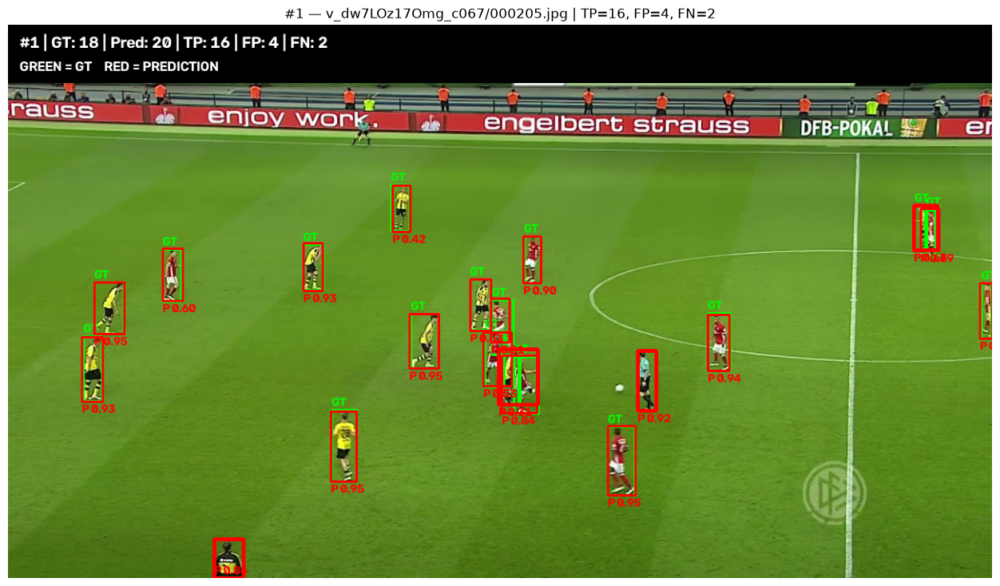

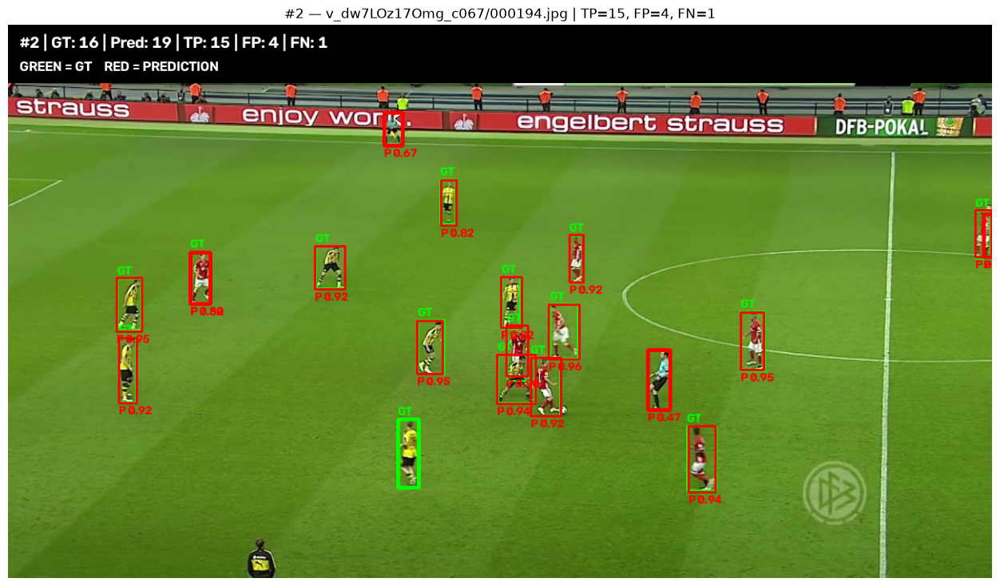

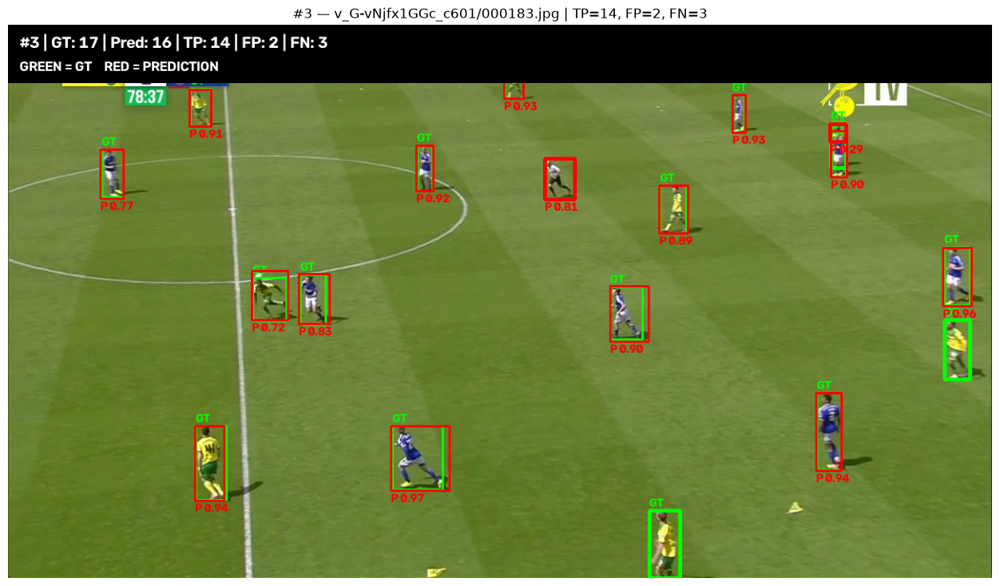

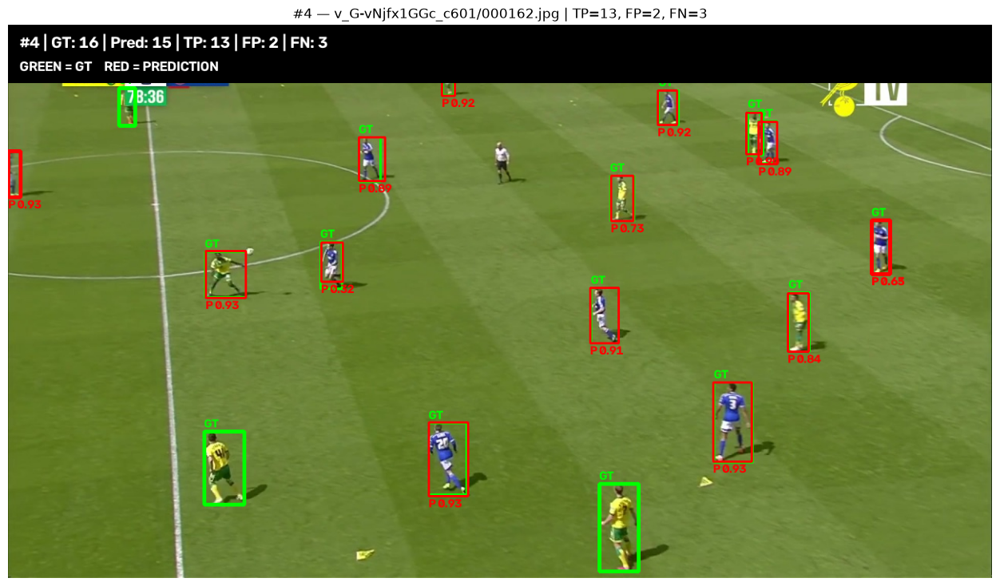

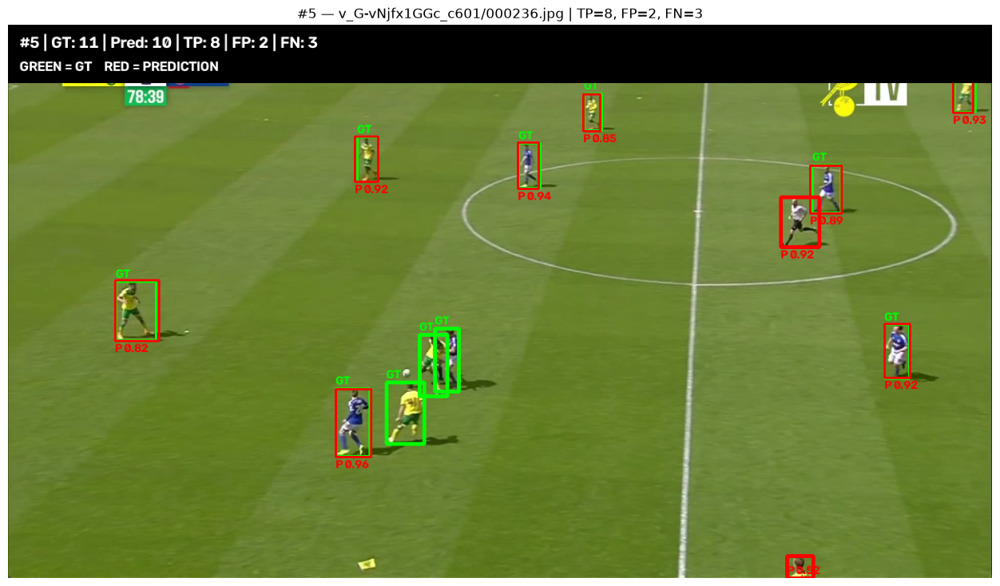

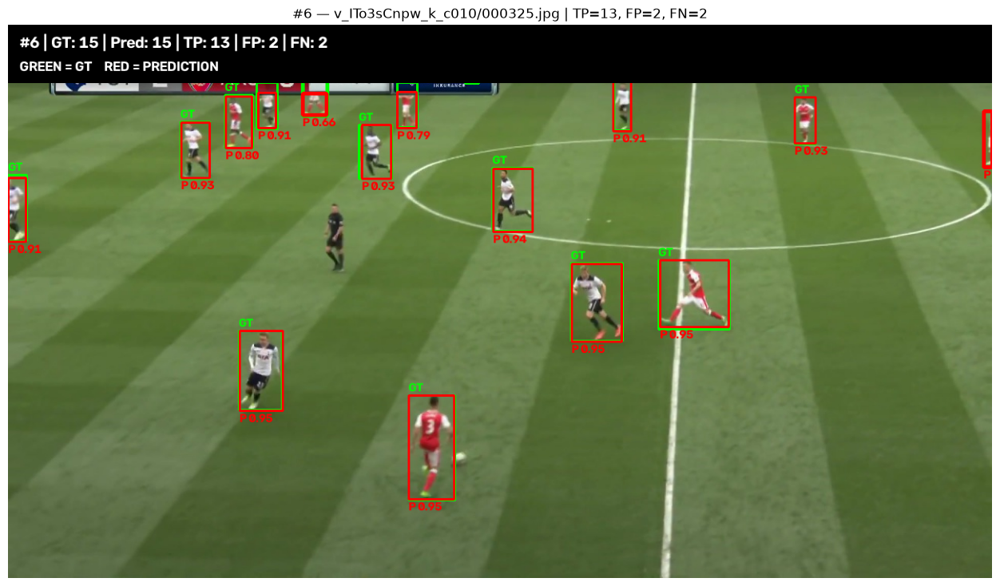

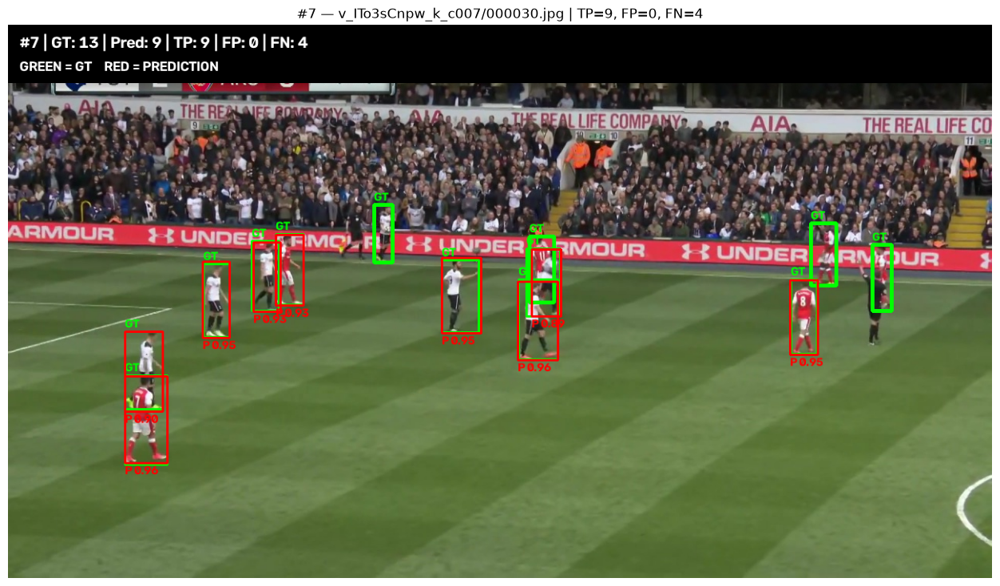

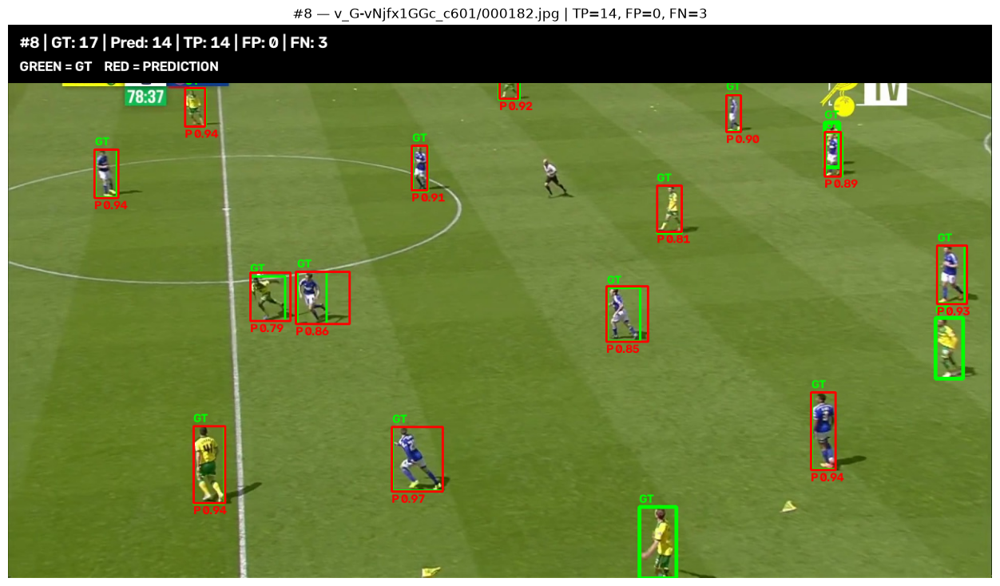

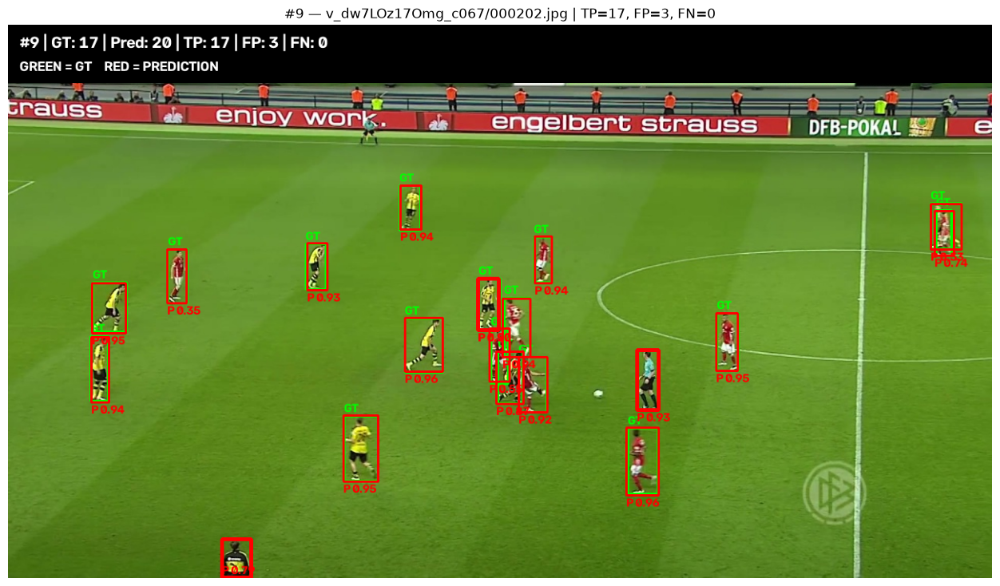

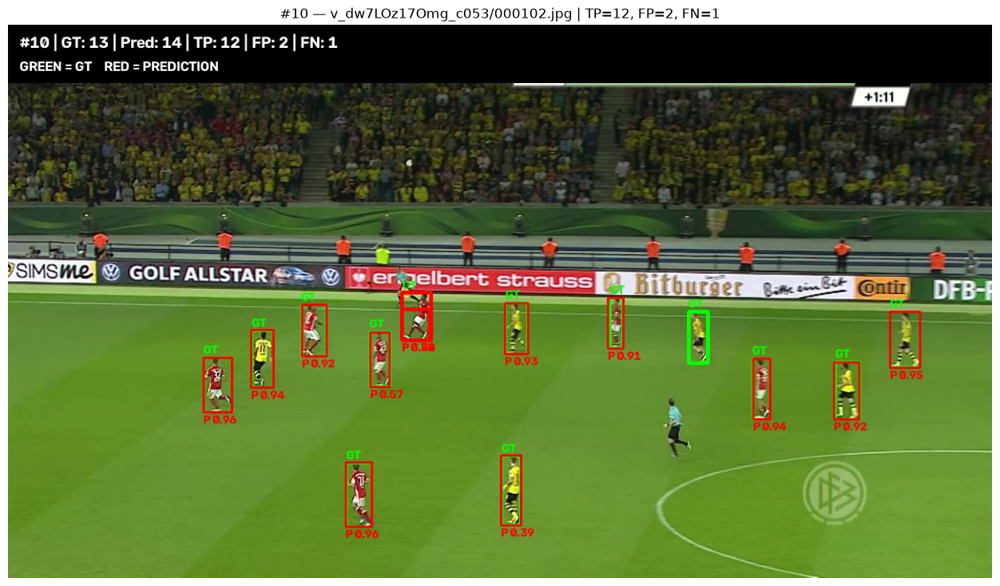


WORST-FRAME VISUALIZATION COMPLETE

Saved to:
/mnt/d/My Projects/AthletiQ/AthletiQ/experiments/yolov26m_sportsmot/failure_analysis/worst_frames


In [22]:
# Cell 20 — Visualize worst YOLOv26m failure cases

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------------------------------------------------
# Configuration
# ---------------------------------------------------------

TOP_K = 10

WORST_DIR = (
    FAILURE_DIR
    / "worst_frames"
)

WORST_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ---------------------------------------------------------
# IoU helper
# ---------------------------------------------------------

def iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter_w = max(0, x2 - x1)
    inter_h = max(0, y2 - y1)

    intersection = inter_w * inter_h

    area1 = max(0, box1[2] - box1[0]) * max(
        0, box1[3] - box1[1]
    )

    area2 = max(0, box2[2] - box2[0]) * max(
        0, box2[3] - box2[1]
    )

    union = area1 + area2 - intersection

    if union <= 0:
        return 0.0

    return intersection / union


# ---------------------------------------------------------
# Get worst frames
# ---------------------------------------------------------

worst_frames = analysis_df.head(TOP_K)

print("Generating visualizations for:")
print()

for rank, row in enumerate(
    worst_frames.itertuples(index=False),
    start=1
):

    print(
        f"{rank:02d}. {row.image} "
        f"(error={row.error}, "
        f"FP={row.false_positive}, "
        f"FN={row.false_negative})"
    )


# ---------------------------------------------------------
# Process each frame
# ---------------------------------------------------------

for rank, row in enumerate(
    worst_frames.itertuples(index=False),
    start=1
):

    image_relative = Path(row.image)

    image_path = (
        YOLO_DIR
        / "images"
        / "val"
        / image_relative
    )

    label_path = (
        YOLO_DIR
        / "labels"
        / "val"
        / image_relative.with_suffix(".txt")
    )

    image = cv2.imread(
        str(image_path)
    )

    if image is None:
        print(
            f"Could not read: {image_path}"
        )
        continue

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    height, width = image.shape[:2]

    # -----------------------------------------------------
    # Load GT
    # -----------------------------------------------------

    gt_boxes = load_yolo_gt(
        label_path,
        width,
        height
    )

    # -----------------------------------------------------
    # Run model
    # -----------------------------------------------------

    result = sportsmot_model.predict(
        source=str(image_path),
        imgsz=1280,
        conf=CONF_THRESHOLD,
        device=0,
        verbose=False
    )[0]

    pred_boxes = []

    if result.boxes is not None:

        for box in result.boxes.xyxy.cpu().numpy():

            pred_boxes.append(
                box.tolist()
            )

    # -----------------------------------------------------
    # Match predictions ↔ GT
    # -----------------------------------------------------

    matched_gt = set()
    matched_pred = set()

    matches = []

    for pred_idx, pred_box in enumerate(pred_boxes):

        best_iou = 0
        best_gt_idx = None

        for gt_idx, gt_box in enumerate(gt_boxes):

            if gt_idx in matched_gt:
                continue

            current_iou = iou(
                pred_box,
                gt_box
            )

            if current_iou > best_iou:
                best_iou = current_iou
                best_gt_idx = gt_idx

        if (
            best_gt_idx is not None
            and best_iou >= IOU_THRESHOLD
        ):

            matched_gt.add(
                best_gt_idx
            )

            matched_pred.add(
                pred_idx
            )

            matches.append(
                (
                    pred_idx,
                    best_gt_idx,
                    best_iou
                )
            )

    # -----------------------------------------------------
    # Draw GT boxes
    # Green = Ground Truth
    # -----------------------------------------------------

    canvas = image.copy()

    for gt_idx, box in enumerate(gt_boxes):

        x1, y1, x2, y2 = map(
            int,
            box
        )

        # Missed GT
        if gt_idx not in matched_gt:
            thickness = 4
        else:
            thickness = 2

        cv2.rectangle(
            canvas,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            thickness
        )

        cv2.putText(
            canvas,
            "GT",
            (x1, max(15, y1 - 5)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 0),
            2
        )

    # -----------------------------------------------------
    # Draw predictions
    # Red = Predictions
    # -----------------------------------------------------

    for pred_idx, box in enumerate(pred_boxes):

        x1, y1, x2, y2 = map(
            int,
            box
        )

        # False positive
        if pred_idx not in matched_pred:
            thickness = 4
        else:
            thickness = 2

        cv2.rectangle(
            canvas,
            (x1, y1),
            (x2, y2),
            (255, 0, 0),
            thickness
        )

        # Confidence
        confidence = float(
            result.boxes.conf[pred_idx].cpu()
        )

        cv2.putText(
            canvas,
            f"P {confidence:.2f}",
            (x1, min(height - 5, y2 + 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (255, 0, 0),
            2
        )

    # -----------------------------------------------------
    # Add title information
    # -----------------------------------------------------

    tp = len(matched_pred)

    fp = len(pred_boxes) - tp

    fn = len(gt_boxes) - tp

    cv2.rectangle(
        canvas,
        (0, 0),
        (width, 75),
        (0, 0, 0),
        -1
    )

    title = (
        f"#{rank} | "
        f"GT: {len(gt_boxes)} | "
        f"Pred: {len(pred_boxes)} | "
        f"TP: {tp} | "
        f"FP: {fp} | "
        f"FN: {fn}"
    )

    cv2.putText(
        canvas,
        title,
        (15, 30),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2
    )

    cv2.putText(
        canvas,
        "GREEN = GT    RED = PREDICTION",
        (15, 60),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (255, 255, 255),
        2
    )

    # -----------------------------------------------------
    # Save
    # -----------------------------------------------------

    output_path = (
        WORST_DIR
        / f"rank_{rank:02d}_"
        f"{image_relative.parent.name}_"
        f"{image_relative.stem}.jpg"
    )

    cv2.imwrite(
        str(output_path),
        cv2.cvtColor(
            canvas,
            cv2.COLOR_RGB2BGR
        )
    )

    # -----------------------------------------------------
    # Display
    # -----------------------------------------------------

    plt.figure(
        figsize=(16, 9)
    )

    plt.imshow(canvas)

    plt.title(
        f"#{rank} — {image_relative} | "
        f"TP={tp}, FP={fp}, FN={fn}"
    )

    plt.axis("off")

    plt.show()


print("\n" + "=" * 60)
print("WORST-FRAME VISUALIZATION COMPLETE")
print("=" * 60)

print("\nSaved to:")
print(WORST_DIR)